Importing the Dependencies

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load Data
df = pd.read_csv("../data/raw/housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


List of numeric columns

In [4]:
# Select only numeric columns (ocean_proximity is text, so it is skipped)
numeric_cols = df.select_dtypes(include="number").columns
numeric_cols

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value'],
      dtype='str')

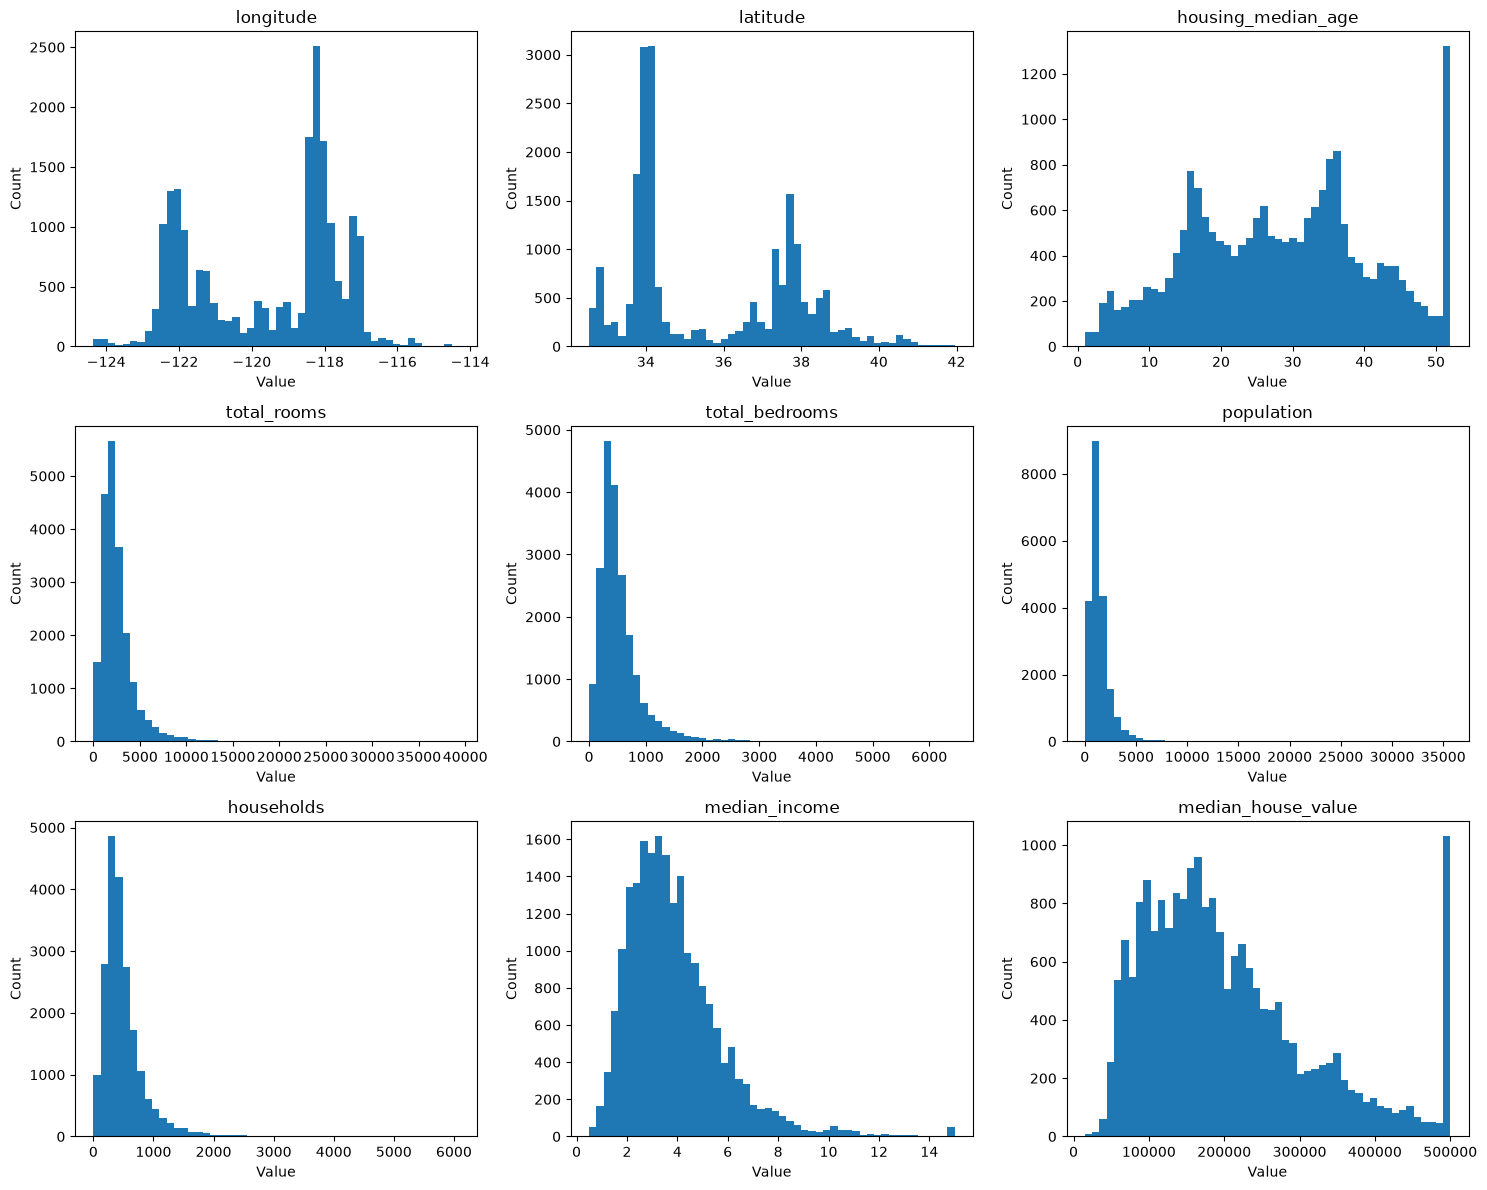

In [6]:
# 3x3 grid of histograms one for each numeric column
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    ax.hist(df[col].dropna(), bins=50)
    ax.set_title(col)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [7]:
# Skewness of every numeric column, from most skewed to least
skew_values = df[numeric_cols].skew().sort_values(ascending=False)
skew_values.round(2)

population            4.94
total_rooms           4.15
total_bedrooms        3.46
households            3.41
median_income         1.65
median_house_value    0.98
latitude              0.47
housing_median_age    0.06
longitude            -0.30
dtype: float64

In [8]:
# Columns with skewness above 1 are considered highly skewed
skewed_cols = skew_values[skew_values > 1].index.tolist()
skewed_cols

['population', 'total_rooms', 'total_bedrooms', 'households', 'median_income']

In [ ]:
# Add median_house_value because 0.98 < 1
skewed_cols = skewed_cols + ["median_house_value"]

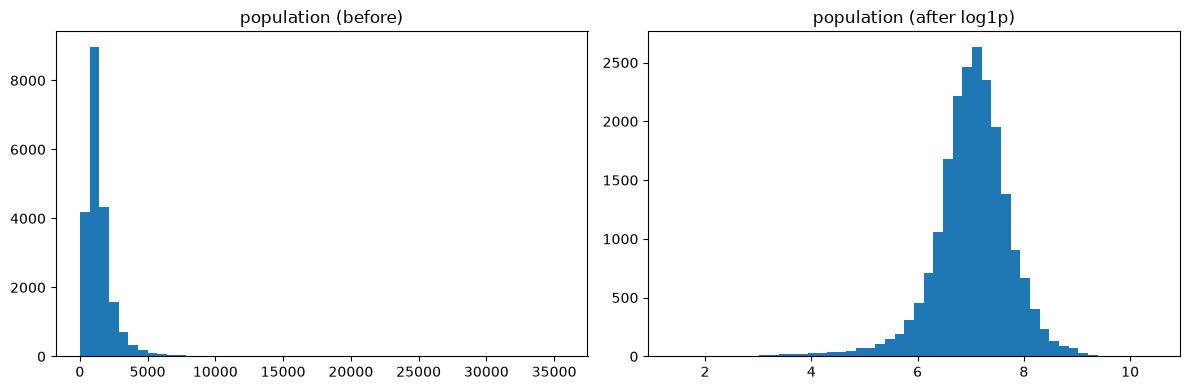

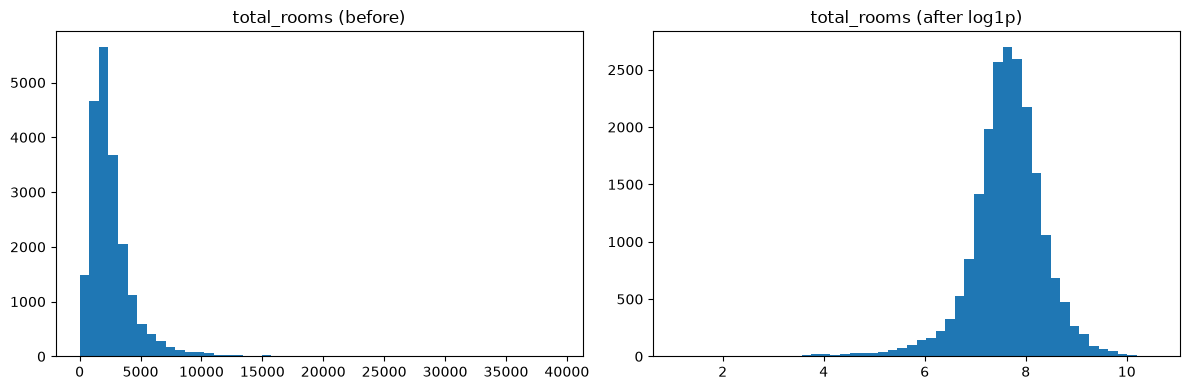

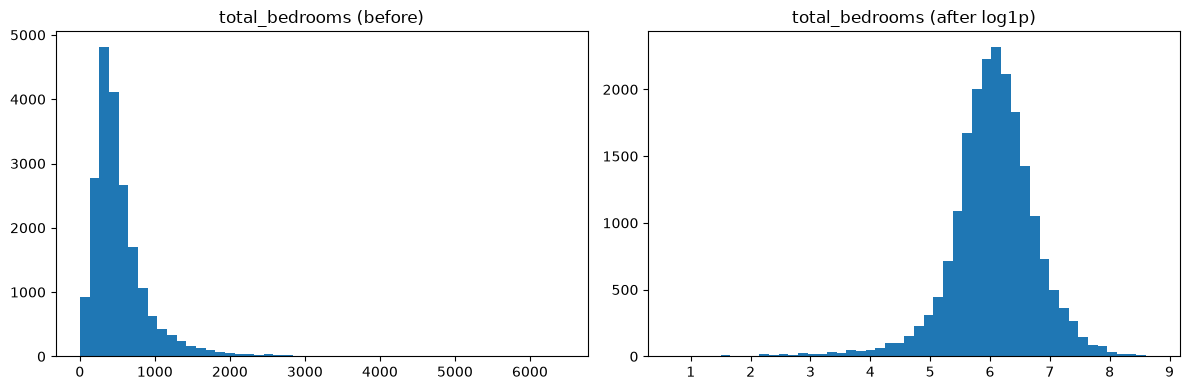

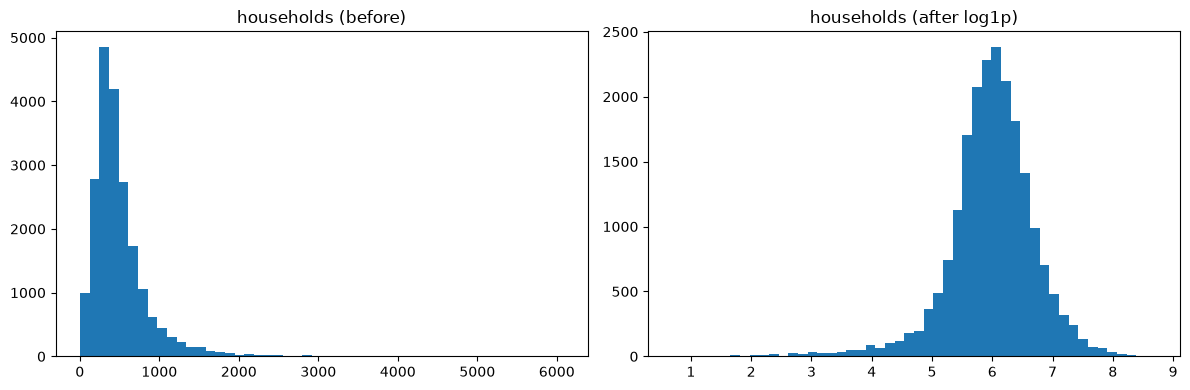

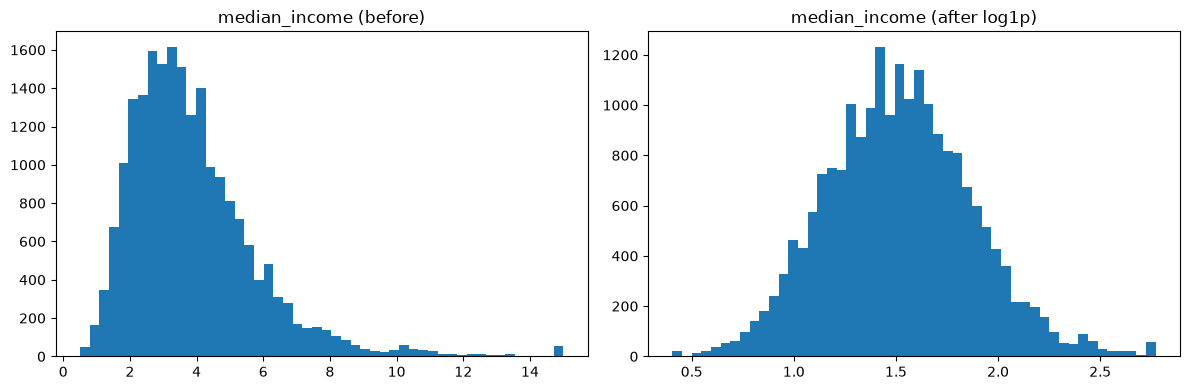

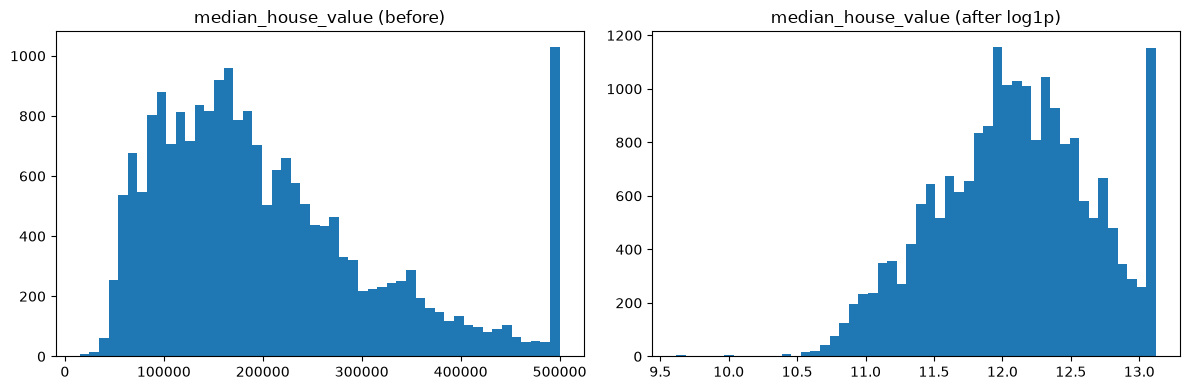

In [14]:
# Compare each skewed column before and after log1p
for col in skewed_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(df[col].dropna(), bins=50)
    axes[0].set_title(f"{col} (before)")

    axes[1].hist(np.log1p(df[col]).dropna(), bins=50)
    axes[1].set_title(f"{col} (after log1p)")

    plt.tight_layout()
    plt.show()

In [ ]:
# Compare table each skewed column before and after log1p
comparison = pd.DataFrame({
    "before": df[skewed_cols].skew(),
    "after_log1p": np.log1p(df[skewed_cols]).skew(),
}).round(2)

comparison

,before,after_log1p
population,4.94,-1.04
total_rooms,4.15,-1.08
total_bedrooms,3.46,-0.99
households,3.41,-1.05
median_income,1.65,0.23
median_house_value,0.98,-0.17
